Installing Required Libraries

In [1]:
!pip install -q pandas numpy matplotlib seaborn openpyxl

Importing Required Libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

print("All libraries imported successfully!")

All libraries imported successfully!


Loading the Online Retail II Dataset

In [3]:
import os

file_path = "/content/online_retail_II.xlsx"

if not os.path.exists(file_path):
    from google.colab import files
    uploaded = files.upload()
    file_path = next(iter(uploaded))

df = pd.read_excel(file_path, engine="openpyxl")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Saving online_retail_II.xlsx to online_retail_II.xlsx
Dataset loaded successfully!
Dataset shape: (525461, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


Dataset Structure and Descriptive Statistics

In [4]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nDescriptive statistics:")
display(df.describe(include="all").T)

Rows: 525461
Columns: 8

Column names:
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 525461 entries, 0 to 525460
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      525461 non-null  object        
 1   StockCode    525461 non-null  object        
 2   Description  522533 non-null  object        
 3   Quantity     525461 non-null  int64         
 4   InvoiceDate  525461 non-null  datetime64[ns]
 5   Price        525461 non-null  float64       
 6   Customer ID  417534 non-null  float64       
 7   Country      525461 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 32.1+ MB

Descriptive statistics:


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
Invoice,525461.0,28816.0,537434.0,675.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,525461,4632,85123A,3516,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,522533,4681,WHITE HANGING HEART T-LIGHT HOLDER,3549,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,525461.0,NaN,NaN,NaN,10.337667,-9600.0,1.0,3.0,10.0,19152.0,107.42411
InvoiceDate,525461,NaN,NaN,NaN,2010-06-28 11:37:36.845017856,2009-12-01 07:45:00,2010-03-21 12:20:00,2010-07-06 09:51:00,2010-10-15 12:45:00,2010-12-09 20:01:00,NaN
Price,525461.0,NaN,NaN,NaN,4.688834,-53594.36,1.25,2.1,4.21,25111.09,146.126914
Customer ID,417534.0,NaN,NaN,NaN,15360.645478,12346.0,13983.0,15311.0,16799.0,18287.0,1680.811316
Country,525461,40,United Kingdom,485852,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Missing Values and Duplicate Analysis

In [5]:
missing_report = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (
        df.isnull().sum() / len(df) * 100
    ).round(2)
})

display(missing_report.sort_values(
    "Missing Percentage", ascending=False
))

print("Exact duplicate rows:", df.duplicated().sum())

,Missing Count,Missing Percentage
Customer ID,107927,20.54
Description,2928,0.56
StockCode,0,0.00
Invoice,0,0.00
Quantity,0,0.00
InvoiceDate,0,0.00
Price,0,0.00
Country,0,0.00


Exact duplicate rows: 6865


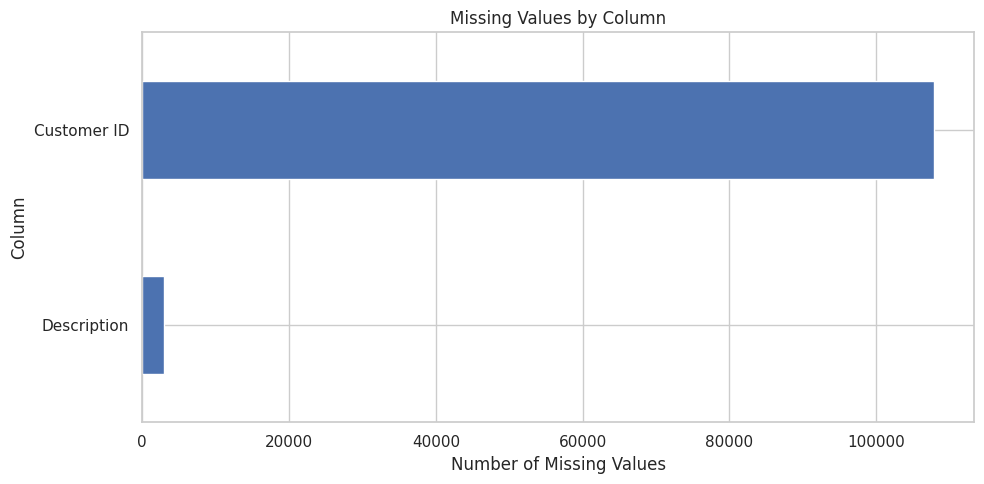

In [6]:
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values()

if not missing.empty:
    missing.plot(kind="barh", figsize=(10, 5))
    plt.title("Missing Values by Column")
    plt.xlabel("Number of Missing Values")
    plt.ylabel("Column")
    plt.tight_layout()
    plt.show()
else:
    print("No missing values found.")

Data Preparation for Exploratory Analysis

In [7]:
eda = df.copy()

eda["InvoiceDate"] = pd.to_datetime(
    eda["InvoiceDate"], errors="coerce"
)
eda["Quantity"] = pd.to_numeric(
    eda["Quantity"], errors="coerce"
)
eda["Price"] = pd.to_numeric(
    eda["Price"], errors="coerce"
)

eda["LineValue"] = eda["Quantity"] * eda["Price"]

# Select valid positive-sales records for sales analysis
sales = eda[
    (eda["Quantity"] > 0) &
    (eda["Price"] > 0) &
    eda["InvoiceDate"].notna()
].copy()

sales["YearMonth"] = (
    sales["InvoiceDate"].dt.to_period("M").astype(str)
)

print("Original records:", len(df))
print("Positive-sales records:", len(sales))
print("Negative-quantity records:", (eda["Quantity"] < 0).sum())

Original records: 525461
Positive-sales records: 511566
Negative-quantity records: 12326


Data Preparation for Exploratory Analysis

In [8]:
eda = df.copy()

eda["InvoiceDate"] = pd.to_datetime(
    eda["InvoiceDate"], errors="coerce"
)
eda["Quantity"] = pd.to_numeric(
    eda["Quantity"], errors="coerce"
)
eda["Price"] = pd.to_numeric(
    eda["Price"], errors="coerce"
)

eda["LineValue"] = eda["Quantity"] * eda["Price"]

# Select valid positive-sales records for sales analysis
sales = eda[
    (eda["Quantity"] > 0) &
    (eda["Price"] > 0) &
    eda["InvoiceDate"].notna()
].copy()

sales["YearMonth"] = (
    sales["InvoiceDate"].dt.to_period("M").astype(str)
)

print("Original records:", len(df))
print("Positive-sales records:", len(sales))
print("Negative-quantity records:", (eda["Quantity"] < 0).sum())

Original records: 525461
Positive-sales records: 511566
Negative-quantity records: 12326


Monthly Sales and Revenue Trends

,YearMonth,Revenue,UnitsSold,Transactions
0,2009-12,825685.760,426981,1682
1,2010-01,652708.502,391525,1105
2,2010-02,553713.306,382782,1202
3,2010-03,833570.131,527401,1681
4,2010-04,681528.992,368198,1462
5,2010-05,659858.860,397206,1500
6,2010-06,752270.140,408636,1645
7,2010-07,650712.940,338920,1529
8,2010-08,697274.910,473420,1425
9,2010-09,924333.011,585357,1839


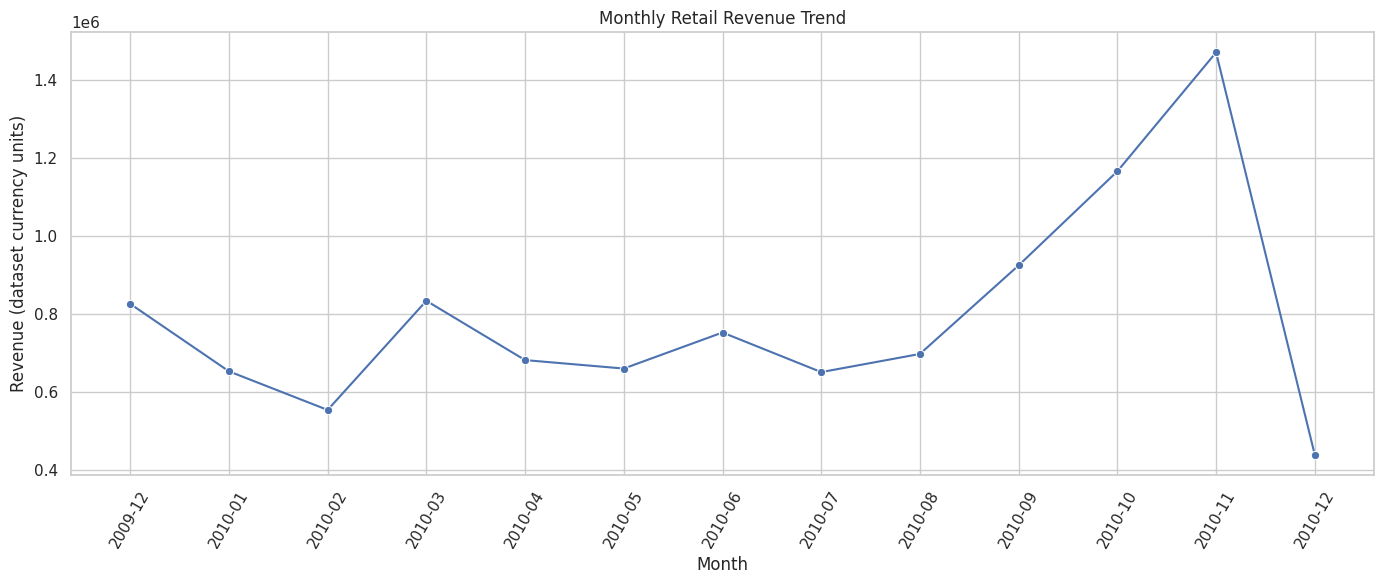

In [9]:
monthly_sales = (
    sales.groupby("YearMonth")
    .agg(
        Revenue=("LineValue", "sum"),
        UnitsSold=("Quantity", "sum"),
        Transactions=("Invoice", "nunique")
    )
    .reset_index()
)

display(monthly_sales.head(12))

plt.figure(figsize=(14, 6))
sns.lineplot(
    data=monthly_sales,
    x="YearMonth",
    y="Revenue",
    marker="o"
)

plt.title("Monthly Retail Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (dataset currency units)")
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()

Top-Selling Products Analysis

,Description,UnitsSold,Revenue,Transactions
0,Manual,2831,262992.08,516
1,REGENCY CAKESTAND 3 TIER,13698,170078.51,2019
2,WHITE HANGING HEART T-LIGHT HOLDER,58792,160630.78,3315
3,DOTCOM POSTAGE,730,116408.71,730
4,ASSORTED COLOUR BIRD ORNAMENT,45348,73092.99,1412
5,PAPER CHAIN KIT 50'S CHRISTMAS,17226,58189.25,957
6,JUMBO BAG RED RETROSPOT,30805,56595.51,1246
7,PARTY BUNTING,10083,49682.72,1013
8,POSTAGE,2310,49477.54,759
9,ROTATING SILVER ANGELS T-LIGHT HLDR,23049,47985.09,347


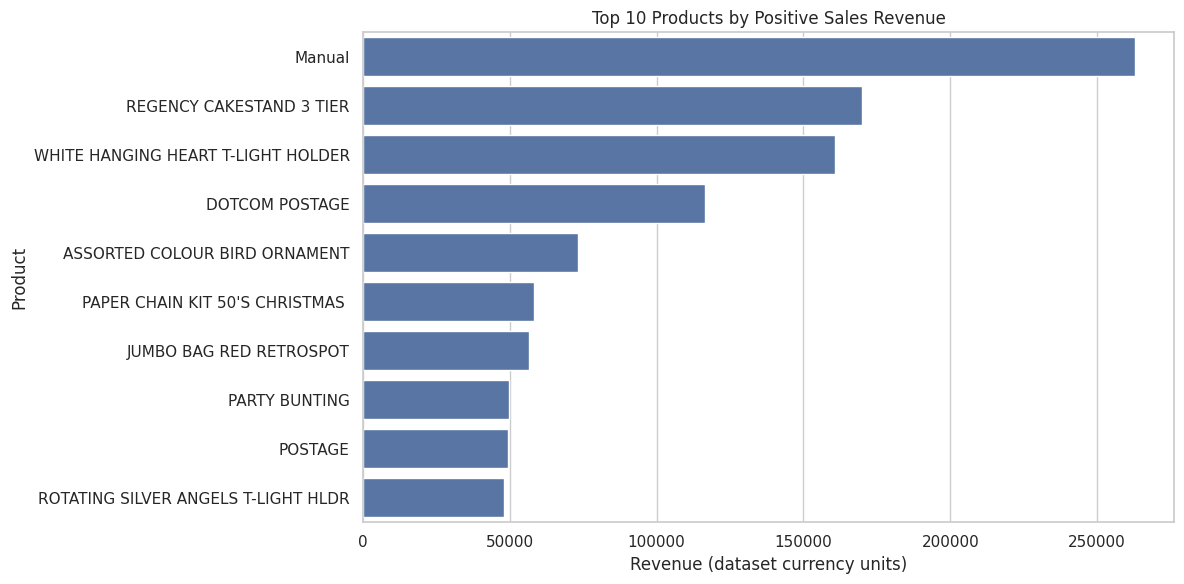

In [10]:
product_sales = (
    sales.groupby("Description")
    .agg(
        UnitsSold=("Quantity", "sum"),
        Revenue=("LineValue", "sum"),
        Transactions=("Invoice", "nunique")
    )
    .sort_values("Revenue", ascending=False)
)

top_products = product_sales.head(10).reset_index()

display(top_products)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=top_products,
    x="Revenue",
    y="Description"
)

plt.title("Top 10 Products by Positive Sales Revenue")
plt.xlabel("Revenue (dataset currency units)")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

Country-Wise Sales Analysis

,Country,Revenue,UnitsSold,Transactions
0,United Kingdom,8846129.263,4720855,19291
1,EIRE,380977.820,193116,348
2,Netherlands,268786.000,183616,135
3,Germany,202395.321,108722,347
4,France,147211.490,163183,241
5,Sweden,53525.390,52567,69
6,Denmark,50906.850,229690,26
7,Spain,47601.420,22856,66
8,Switzerland,43921.390,22255,40
9,Australia,31446.800,20189,40


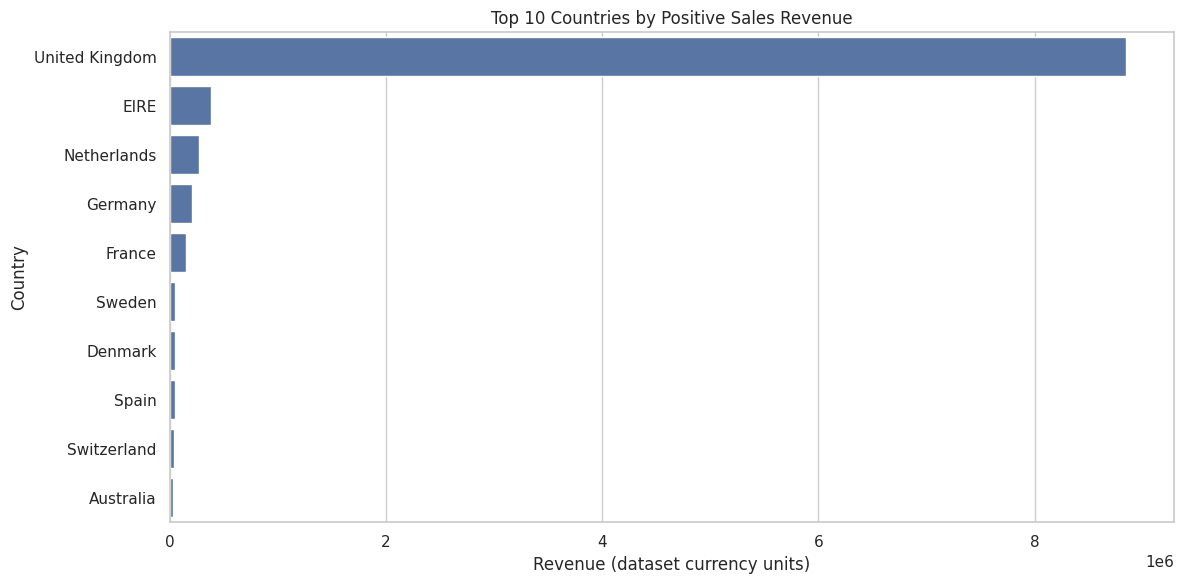

In [11]:
country_sales = (
    sales.groupby("Country")
    .agg(
        Revenue=("LineValue", "sum"),
        UnitsSold=("Quantity", "sum"),
        Transactions=("Invoice", "nunique")
    )
    .sort_values("Revenue", ascending=False)
)

top_countries = country_sales.head(10).reset_index()

display(top_countries)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=top_countries,
    x="Revenue",
    y="Country"
)

plt.title("Top 10 Countries by Positive Sales Revenue")
plt.xlabel("Revenue (dataset currency units)")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

Distribution Analysis and Outlier Detection

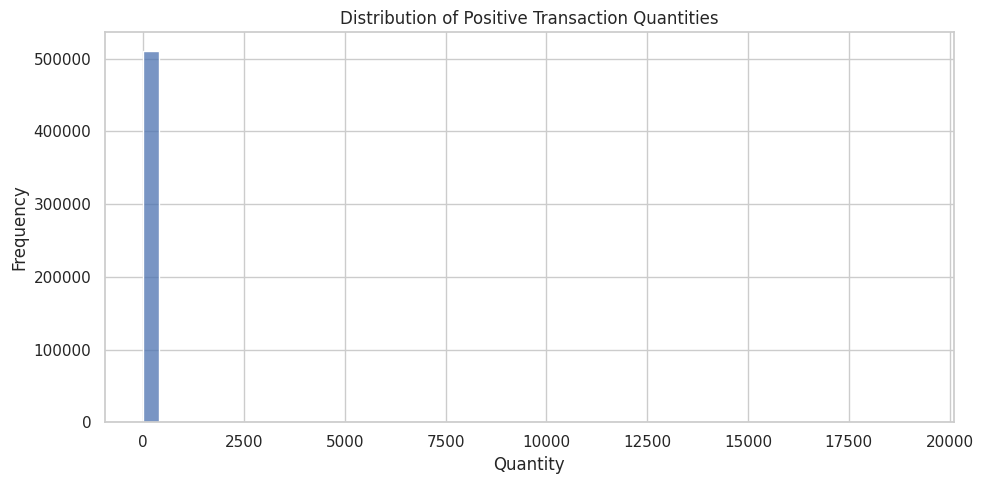

In [12]:
plt.figure(figsize=(10, 5))
sns.histplot(data=sales, x="Quantity", bins=50)

plt.title("Distribution of Positive Transaction Quantities")
plt.xlabel("Quantity")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

In [13]:
q1 = sales["Quantity"].quantile(0.25)
q3 = sales["Quantity"].quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outliers = sales[
    (sales["Quantity"] < lower_bound) |
    (sales["Quantity"] > upper_bound)
]

print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Potential outliers:", len(outliers))

display(outliers[
    ["Invoice", "Description", "Quantity", "Price"]
].head(10))

Lower bound: -12.5
Upper bound: 23.5
Potential outliers: 54978


,Invoice,Description,Quantity,Price
3,489434,"RECORD FRAME 7"" SINGLE SIZE",48,2.10
4,489434,STRAWBERRY CERAMIC TRINKET BOX,24,1.25
5,489434,PINK DOUGHNUT TRINKET POT,24,1.65
6,489434,SAVE THE PLANET MUG,24,1.25
10,489435,HEART MEASURING SPOONS LARGE,24,1.65
30,489436,SCOTTIE DOG HOT WATER BOTTLE,24,4.25
54,489438,DINOSAURS WRITING SET,28,0.98
55,489438,SET OF MEADOW FLOWER STICKERS,30,1.69
56,489438,CHARLIE AND LOLA CHARLOTTE BAG,30,1.15
57,489438,JUMBO BAG CHARLIE AND LOLA TOYS,30,2.00


Correlation and Relationship Analysis

,Quantity,Price,LineValue
Quantity,1.00000,-0.005130,0.325230
Price,-0.00513,1.000000,0.699033
LineValue,0.32523,0.699033,1.000000


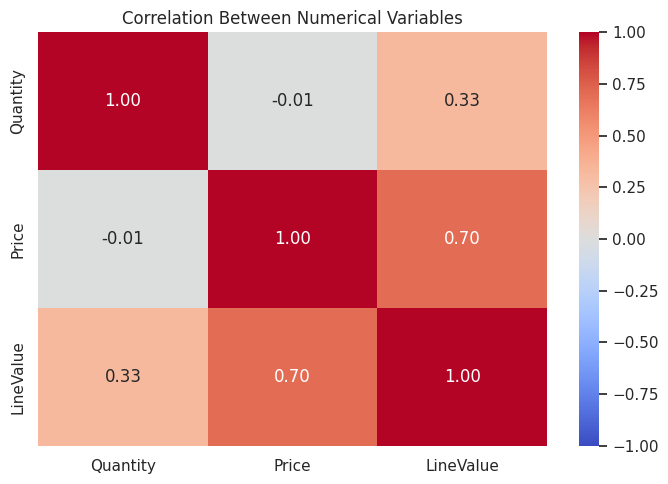

In [14]:
correlation = sales[
    ["Quantity", "Price", "LineValue"]
].corr()

display(correlation)

plt.figure(figsize=(7, 5))
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Numerical Variables")
plt.tight_layout()
plt.show()

Business Questions and Evidence-Based Answers

In [15]:
best_month = monthly_sales.loc[
    monthly_sales["Revenue"].idxmax()
]

print("1. Highest-revenue month:")
print(best_month.to_dict())

print("\n2. Top product by positive sales revenue:")
display(product_sales.head(1))

print("\n3. Top country by positive sales revenue:")
display(country_sales.head(1))

print("\n4. Number of positive-sales records:")
print(len(sales))

print("\n5. Number of potential quantity outliers:")
print(len(outliers))

1. Highest-revenue month:
{'YearMonth': '2010-11', 'Revenue': 1470272.482, 'UnitsSold': 728449, 'Transactions': 2747}

2. Top product by positive sales revenue:


,UnitsSold,Revenue,Transactions
Description,,,
Manual,2831,262992.08,516



3. Top country by positive sales revenue:


,Revenue,UnitsSold,Transactions
Country,,,
United Kingdom,8846129.263,4720855,19291



4. Number of positive-sales records:
511566

5. Number of potential quantity outliers:
54978
